# Cluster State Circuit — Entanglement Generation (Qiskit)

**Primitive:** Linear 4-qubit cluster (graph) state generation

## SETUP (must match the CUDA-Q notebook exactly)
- N QUBITS: 4
- Gate sequence: H on every qubit (q0,q1,q2,q3), then CZ(0,1), CZ(1,2), CZ(2,3) — a **linear cluster graph**: 0—1—2—3
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring. This is Qiskit's native convention, so **no reversal is needed in this notebook**.
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE CONVENTION: normalize so the first nonzero amplitude, in ascending bitstring order, is rotated to be real and positive.
- Basis ordering for matrices/vectors: `{|0000>, |0001>, ..., |1111>}` ascending binary order.

## Theory recap
A cluster state is prepared by (1) putting every qubit into `|+> = H|0>`, then (2) applying a
**CZ gate along every edge of a graph** G. For a linear graph on qubits `0-1-2-3` the state is

`|C4> = (CZ_{2,3} · CZ_{1,2} · CZ_{0,1}) (H⊗H⊗H⊗H) |0000>`

Because H and CZ are both real-valued gates, every amplitude of `|C4>` is real and equal to
`±1/4` (16 basis states, each with probability exactly `1/16`). The sign of each amplitude is
`(-1)^{x0 x1 + x1 x2 + x2 x3}` where `x_k` is the value of qubit k in the bitstring.

The state is stabilized by `K_i = X_i · Z_{i-1} · Z_{i+1}` (dropping the Z factor for a
qubit with no neighbor on that side) — this is what makes it a genuine multi-qubit
entangled resource state (used e.g. in measurement-based quantum computing).

**Run all cells top to bottom.**

In [2]:
# Install cell — exact package names for the current stable Qiskit release.
# qiskit-aer is the high-performance simulator backend (AerSimulator).
# pylatexenc is required by circuit.draw(output="mpl") for gate-label rendering.
!pip install -q qiskit qiskit-aer pylatexenc


In [3]:
# Imports + constants
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

N_QUBITS = 4
SHOTS = 10000
SEED = 42

print(f"N_QUBITS = {N_QUBITS}")
print(f"SHOTS    = {SHOTS}")
print(f"SEED     = {SEED}")


N_QUBITS = 4
SHOTS    = 10000
SEED     = 42


In [4]:
# Build the linear cluster-state circuit, gate by gate.
qc = QuantumCircuit(N_QUBITS, name="cluster_state")

# Step 1: put every qubit into |+> = H|0> — this is the "input" layer of the cluster state.
qc.h(0)  # qubit 0 -> |+>
qc.h(1)  # qubit 1 -> |+>
qc.h(2)  # qubit 2 -> |+>
qc.h(3)  # qubit 3 -> |+>

# Step 2: apply a CZ gate along every edge of the linear graph 0-1-2-3.
# CZ entangles the two qubits by flipping the sign of the amplitude whenever BOTH are |1>.
qc.cz(0, 1)  # edge (0,1)
qc.cz(1, 2)  # edge (1,2)
qc.cz(2, 3)  # edge (2,3)

print(qc)


     ┌───┐         
q_0: ┤ H ├─■───────
     ├───┤ │       
q_1: ┤ H ├─■──■────
     ├───┤    │    
q_2: ┤ H ├────■──■─
     ├───┤       │ 
q_3: ┤ H ├───────■─
     └───┘         


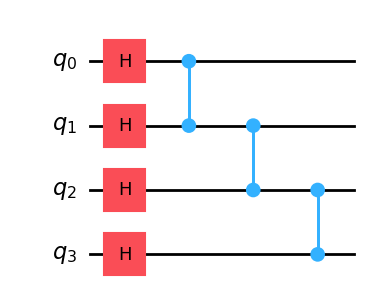

In [5]:
# Draw the circuit with matplotlib and save to disk.
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig(f"cluster_state_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [6]:
# Explicit matrix representation — built TWO ways and cross-checked.
# Basis ordering for all matrices below: {|0000>, |0001>, ..., |1111>} ascending binary,
# with qubit 0 as the LEAST significant (rightmost) bit — Qiskit's native tensor ordering.

H = (1/np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
I2 = np.eye(2, dtype=complex)

def cz_matrix(n_qubits, control, target):
    """Full 2^n x 2^n CZ matrix in Qiskit's little-endian (qubit0 = LSB) ordering."""
    dim = 2 ** n_qubits
    mat = np.eye(dim, dtype=complex)
    for i in range(dim):
        bit_c = (i >> control) & 1
        bit_t = (i >> target) & 1
        if bit_c == 1 and bit_t == 1:
            mat[i, i] = -1
    return mat

# (a) Manual construction: kron(H,H,H,H) with qiskit's convention that qubit 0 is the
# rightmost tensor factor, i.e. full_H = H(q3) kron H(q2) kron H(q1) kron H(q0)
H_full = np.kron(np.kron(np.kron(H, H), H), H)
CZ01 = cz_matrix(N_QUBITS, 0, 1)
CZ12 = cz_matrix(N_QUBITS, 1, 2)
CZ23 = cz_matrix(N_QUBITS, 2, 3)
U_manual = CZ23 @ CZ12 @ CZ01 @ H_full

# (b) Framework extraction: qiskit.quantum_info.Operator reads the circuit's own unitary,
# already in Qiskit's little-endian convention.
U_qiskit = Operator(qc).data

match = np.allclose(U_manual, U_qiskit, atol=1e-9)
print("Manual U (top-left 4x4 block, rounded to 4 dp):")
print(np.round(U_manual[:4, :4], 4))
print()
print("Operator(qc) (top-left 4x4 block, rounded to 4 dp):")
print(np.round(U_qiskit[:4, :4], 4))
print()
print(f"Manual construction matches Operator(qc) exactly: {match}")
assert match, "Manual matrix and Qiskit Operator matrix disagree!"


Manual U (top-left 4x4 block, rounded to 4 dp):
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

Operator(qc) (top-left 4x4 block, rounded to 4 dp):
[[ 0.25+0.j  0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j -0.25+0.j]
 [ 0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [-0.25+0.j  0.25+0.j  0.25+0.j -0.25+0.j]]

Manual construction matches Operator(qc) exactly: True


In [7]:
# Exact statevector, with global-phase normalization.

def normalize_global_phase(vec):
    """Rotate so the first amplitude (ascending index / ascending bitstring order)
    with |amp| > 1e-9 is real and positive."""
    vec = np.array(vec, dtype=complex)
    for amp in vec:
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            return vec * np.exp(-1j * phase)
    return vec

sv = Statevector.from_instruction(qc)
amps = normalize_global_phase(sv.data)

# Qiskit already prints bitstrings with qubit 0 as the rightmost bit — no reversal needed.
prob_dict = {}
for i, amp in enumerate(amps):
    bitstring = format(i, f"0{N_QUBITS}b")  # qubit(N-1)...qubit0, i.e. qubit0 = rightmost char
    prob_dict[bitstring] = float(np.round(abs(amp) ** 2, 6))
    print(f"{bitstring}: amplitude = {amp.real:+.4f}{amp.imag:+.4f}j   prob = {prob_dict[bitstring]:.4f}")

prob_dict = dict(sorted(prob_dict.items()))
print()
print("Sum of probabilities:", round(sum(prob_dict.values()), 6))


0000: amplitude = +0.2500+0.0000j   prob = 0.0625
0001: amplitude = +0.2500+0.0000j   prob = 0.0625
0010: amplitude = +0.2500+0.0000j   prob = 0.0625
0011: amplitude = -0.2500+0.0000j   prob = 0.0625
0100: amplitude = +0.2500+0.0000j   prob = 0.0625
0101: amplitude = +0.2500+0.0000j   prob = 0.0625
0110: amplitude = -0.2500+0.0000j   prob = 0.0625
0111: amplitude = +0.2500+0.0000j   prob = 0.0625
1000: amplitude = +0.2500+0.0000j   prob = 0.0625
1001: amplitude = +0.2500+0.0000j   prob = 0.0625
1010: amplitude = +0.2500+0.0000j   prob = 0.0625
1011: amplitude = -0.2500+0.0000j   prob = 0.0625
1100: amplitude = -0.2500+0.0000j   prob = 0.0625
1101: amplitude = -0.2500+0.0000j   prob = 0.0625
1110: amplitude = +0.2500+0.0000j   prob = 0.0625
1111: amplitude = -0.2500+0.0000j   prob = 0.0625

Sum of probabilities: 1.0


**Ordering-fix note (Qiskit):** No bitstring reversal was applied. Qiskit's own
`Statevector`, `Operator`, and `get_counts()` all index amplitudes/bitstrings with
**qubit 0 as the least-significant (rightmost) bit** by construction, which is exactly the
QUBIT ORDERING CONTRACT declared in the SETUP block above. The CUDA-Q notebook has to
explicitly reverse its bitstrings to match this convention — see its own ordering-fix cell.

In [8]:
# Measurement / sampling cell — shared SEED and SHOTS.
qc_meas = qc.copy()
qc_meas.measure_all()

sim = AerSimulator(seed_simulator=SEED)
tqc = transpile(qc_meas, sim)
job = sim.run(tqc, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

# Qiskit counts keys already use qubit0 = rightmost bit -> no reversal needed.
measured_probs = {bitstring: c / SHOTS for bitstring, c in counts.items()}
measured_probs = dict(sorted(measured_probs.items()))
print("Measured probabilities (from", SHOTS, "shots):")
for k, v in measured_probs.items():
    print(f"  {k}: {v:.4f}")


Measured probabilities (from 10000 shots):
  0000: 0.0589
  0001: 0.0662
  0010: 0.0633
  0011: 0.0625
  0100: 0.0632
  0101: 0.0618
  0110: 0.0692
  0111: 0.0638
  1000: 0.0593
  1001: 0.0575
  1010: 0.0625
  1011: 0.0644
  1100: 0.0621
  1101: 0.0617
  1110: 0.0592
  1111: 0.0644


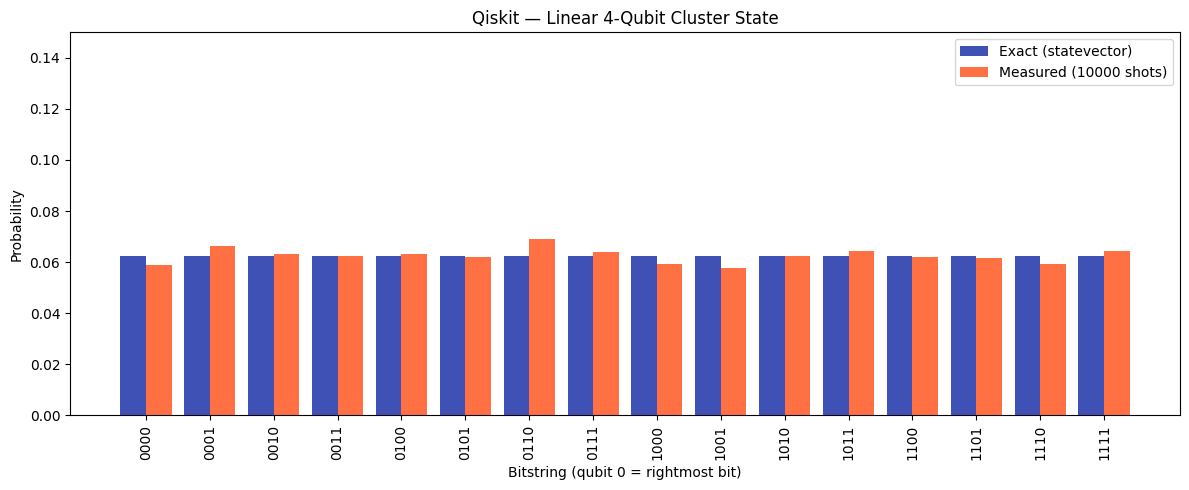

In [9]:
# Histogram cell — matplotlib bar chart, saved to disk.
all_keys = sorted(prob_dict.keys())
exact_vals = [prob_dict[k] for k in all_keys]
meas_vals = [measured_probs.get(k, 0.0) for k in all_keys]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(all_keys))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="Exact (statevector)", color="#3f51b5")
ax.bar(x + width/2, meas_vals, width, label=f"Measured ({SHOTS} shots)", color="#ff7043")
ax.set_xticks(x)
ax.set_xticklabels(all_keys, rotation=90)
ax.set_ylim(0, 0.15)
ax.set_xlabel("Bitstring (qubit 0 = rightmost bit)")
ax.set_ylabel("Probability")
ax.set_title("Qiskit — Linear 4-Qubit Cluster State")
ax.legend()
fig.tight_layout()
fig.savefig(f"cluster_state_qiskit_histogram.png", dpi=150, bbox_inches="tight")
plt.show()


In [10]:
# Resource counts.
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))


Circuit depth: 4
Gate counts: {'h': 4, 'cz': 3}


In [11]:
# Convention-notes cell (plain text restatement).
print("QUBIT ORDERING: qubit 0 = rightmost bit in every bitstring above; Qiskit's native")
print("convention, so no reversal was applied anywhere in this notebook.")
print("GLOBAL PHASE: normalized so the first nonzero amplitude in ascending bitstring")
print("order (here, |0000>) is rotated to be real and positive. All amplitudes in this")
print("particular state are already real, so normalization had no visible effect.")


QUBIT ORDERING: qubit 0 = rightmost bit in every bitstring above; Qiskit's native
convention, so no reversal was applied anywhere in this notebook.
GLOBAL PHASE: normalized so the first nonzero amplitude in ascending bitstring
order (here, |0000>) is rotated to be real and positive. All amplitudes in this
particular state are already real, so normalization had no visible effect.


In [12]:
# Final result cell.
# QISKIT_RESULT holds the EXACT statevector-derived probability dictionary (deterministic,
# not subject to shot noise), so it can be diffed directly against CUDAQ_RESULT.
QISKIT_RESULT = prob_dict
print(QISKIT_RESULT)


{'0000': 0.0625, '0001': 0.0625, '0010': 0.0625, '0011': 0.0625, '0100': 0.0625, '0101': 0.0625, '0110': 0.0625, '0111': 0.0625, '1000': 0.0625, '1001': 0.0625, '1010': 0.0625, '1011': 0.0625, '1100': 0.0625, '1101': 0.0625, '1110': 0.0625, '1111': 0.0625}


In [13]:
# Diff-check block (uncomment the CUDAQ_RESULT import/paste to run the cross-check).
#
# Hand-computed expectation: a 4-qubit linear cluster state has 16 equally likely outcomes,
# each with probability exactly 1/16 = 0.0625. The signs of the amplitudes alternate as
# (-1)^(x0*x1 + x1*x2 + x2*x3), but probabilities (|amplitude|^2) are uniform regardless
# of sign, so QISKIT_RESULT should already satisfy:
expected_uniform = {k: 1/16 for k in QISKIT_RESULT}
max_delta_vs_hand = max(abs(QISKIT_RESULT[k] - expected_uniform[k]) for k in QISKIT_RESULT)
print("Max |QISKIT_RESULT - hand-computed uniform 1/16| =", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# CUDAQ_RESULT = { ... }  # paste CUDA-Q notebook's final dict here to cross-check
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print("Max probability delta Qiskit vs CUDA-Q:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance!"


Max |QISKIT_RESULT - hand-computed uniform 1/16| = 0.0
